# Buy & Hold benchmarks — SPY, TLT, ES3, BTC (daily bars)

**Rule**: put the whole account into one asset at the **open of the first day**, hold, and sell at the
**close of the last day**. Two orders in total, each paying that asset's commission + 2 bps slippage.

This is the bar every active strategy in the group has to beat. It reuses the shared trade-tracker
engine (`run_backtest`, `buy_and_hold`, `compute_metrics`) so the metric names and definitions match
`strategy_btc_buy_and_hold.ipynb` exactly.

What's in here:

1. **Headline table** — buy & hold on the test period, one column per asset
2. Every period (full / train / val / test) per asset, same split dates as the BTC notebook
3. **Total return vs price-only** — why dividend-adjusted prices matter (TLT especially)
4. Equal-weight portfolio benchmarks (the bar for the combined strategy)
5. Charts, and saved CSVs in `model/results/`

Choices made (change in *Settings*):

* **Daily bars**, built from the team's 30-min canonical file (first open / last close of each session).
* **Dividend-adjusted** prices by default (`USE_ADJUSTED = True`): SPY and TLT pay dividends, and
  holding the ETF earns them, so the honest benchmark is total return.
* Annualisation: 252 trading days for SPY / TLT / ES3, 365 for BTC (trades every day).
* ES3 returns are in **SGD** (no USD/SGD conversion); the others are in USD.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


def find_repo_root(start: Path = Path.cwd()) -> Path:
    # Walk up from the notebook folder until the folder holding all AlgoGoneCrazy-dev-* repos.
    for p in [start, *start.parents]:
        if (p / "AlgoGoneCrazy-dev-trade-tracker").is_dir():
            return p
    raise FileNotFoundError("Could not find AlgoGoneCrazy-dev-trade-tracker above " + str(start))


REPO_ROOT = find_repo_root()
TRACKER_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-trade-tracker"   # backtest engine + metrics
MODEL_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-model" / "model"
RESULTS_DIR = MODEL_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

if str(TRACKER_DIR) not in sys.path:
    sys.path.insert(0, str(TRACKER_DIR))
from src.backtest import run_portfolio_backtest
from src.tracker import CostModel
from src.metrics import compute_metrics, drawdown_series

print("repo root   :", REPO_ROOT)

repo root   : /home/claude/work/Githubrepo


## 1. Settings

In [2]:
INITIAL_CASH = 100_000.0
SLIPPAGE_BPS = 2.0            # half-spread + impact per order, same as the BTC notebooks
USE_ADJUSTED = True           # True = total return (dividends reinvested), False = price only

# --- split dates: same boundaries as strategy_btc_buy_and_hold.ipynb (70 / 15 / 15 of the BTC bars)
TRAIN_END = "2025-10-22"      # last day of train
VAL_END = "2026-04-05"        # last day of validation; test starts the next day

# --- trading days per year for annualising
PERIODS_PER_YEAR = {"SPY": 252, "TLT": 252, "ES3": 252, "BTC": 365}

# --- commissions, from AlgoGoneCrazy-dev-data/config/cost_assumptions.json
#   SPY / TLT : IBKR Pro Tiered, USD 0.0035 per share, min USD 0.35, capped at 1% of trade value
#   ES3       : IBKR SGX, 0.08% of trade value, min SGD 2.50, + 0.2 bp IdealPro FX conversion
#   BTC       : Binance spot 0.10%, no BNB discount
COSTS = {
    "SPY": {"per_share": 0.0035, "min_fee": 0.35, "cap_pct": 0.01},
    "TLT": {"per_share": 0.0035, "min_fee": 0.35, "cap_pct": 0.01},
    "ES3": {"pct": 0.0008 + 0.00002, "min_fee": 2.50},
    "BTC": {"pct": 0.0010, "min_fee": 0.0},
}

# Optional: pull a longer ES3 daily history from Yahoo (the team file only covers ~2.5 months).
# Needs `pip install yfinance` and internet; silently skipped otherwise.
TRY_YFINANCE_ES3 = True
TAG = "benchmark_bh"

## 2. Load the team's 30-min bars

Looks for the team OneDrive folder `...FE5209_Group_Project/data/` (or set the `FE5209_DATA_DIR`
environment variable / `DATA_DIR` below), takes the **newest dated snapshot's** canonical file for
SPY / TLT / BTC, and stitches **every** snapshot's ES3 file together because each one only holds
Yahoo's last ~60 days.

In [3]:
DATA_DIR = None   # set a full path here to override the search below


def find_data_dir() -> Path:
    if DATA_DIR:
        return Path(DATA_DIR)
    if os.environ.get("FE5209_DATA_DIR"):
        return Path(os.environ["FE5209_DATA_DIR"])
    for base in (Path.home() / "National University of Singapore", REPO_ROOT.parent, REPO_ROOT):
        if base.is_dir():
            hits = sorted(base.glob("*FE5209_Group_Project/data"))
            if hits:
                return hits[0]
    raise FileNotFoundError("Team data folder not found - set DATA_DIR")


data_dir = find_data_dir()
snapshots = sorted(p for p in data_dir.iterdir() if p.is_dir() and p.name.isdigit())
latest = snapshots[-1]
print("data folder :", data_dir)
print("snapshots   :", [p.name for p in snapshots], "-> using", latest.name)

USECOLS = ["source_symbol", "bar_open_time_utc", "session_date_local", "open", "high", "low",
           "close", "adjusted_close", "volume"]
canon = pd.read_csv(latest / "canonical" / "market_bars_30m.csv", usecols=USECOLS, low_memory=False)

# ES3: every 30-min file from every snapshot, newest snapshot wins on overlapping bars
es3_files = [f for s in snapshots for f in s.rglob("*.csv")
             if f.name in ("market_bars_30m_with_backfill.csv", "market_bars_30m.csv")
             and ("ES3" in str(f) or f.parent == s)]
parts = []
for f in es3_files:
    d = pd.read_csv(f, low_memory=False)
    d = d[d["source_symbol"].astype(str).str.contains("ES3")]
    if len(d):
        parts.append(d[USECOLS].assign(snapshot=f.relative_to(data_dir).parts[0],
                                       backfill=int("with_backfill" in f.name)))
es3_30m = (pd.concat(parts).sort_values(["snapshot", "backfill"])
           .drop_duplicates("bar_open_time_utc", keep="last").drop(columns=["snapshot", "backfill"]))

bars30 = pd.concat([canon[~canon["source_symbol"].str.contains("ES3")], es3_30m])
bars30["asset"] = bars30["source_symbol"].map({"SPY": "SPY", "TLT": "TLT", "BTCUSDT": "BTC", "ES3.SI": "ES3"})
bars30.groupby("asset")["bar_open_time_utc"].agg(["min", "max", "count"])

data folder : /mnt/user-data/uploads/data
snapshots   : ['260831', '260903', '260918'] -> using 260918


,min,max,count
asset,,,
BTC,2023-09-17 00:00:00+00:00,2026-09-16 23:30:00+00:00,52608
ES3,2026-07-01 05:00:00+00:00,2026-09-15 08:30:00+00:00,750
SPY,2023-09-18 13:30:00+00:00,2026-09-16 19:30:00+00:00,9734
TLT,2023-09-18 13:30:00+00:00,2026-09-16 19:30:00+00:00,9734


## 3. 30-min → daily bars

One bar per local session date: open = first 30-min open, close = last 30-min close.
With `USE_ADJUSTED`, both are scaled by that bar's `adjusted_close / close` factor so dividends
show up as return instead of a price drop.

In [4]:
def to_daily(b: pd.DataFrame, adjusted: bool) -> pd.DataFrame:
    b = b.sort_values("bar_open_time_utc").copy()
    f = (b["adjusted_close"] / b["close"]) if adjusted else 1.0
    for c in ("open", "high", "low", "close"):
        b[c] = b[c] * f
    g = b.groupby("session_date_local")
    d = pd.DataFrame({"open": g["open"].first(), "high": g["high"].max(), "low": g["low"].min(),
                      "close": g["close"].last(), "volume": g["volume"].sum()})
    d.index = pd.DatetimeIndex(pd.to_datetime(d.index), name="date")
    return d


_yf_cache = {}


def load_es3_yfinance(adjusted: bool) -> pd.DataFrame | None:
    if not TRY_YFINANCE_ES3:
        return None
    if adjusted in _yf_cache:
        return _yf_cache[adjusted]
    _yf_cache[adjusted] = None
    try:
        import yfinance as yf
        y = yf.download("ES3.SI", start="2023-09-18", interval="1d", auto_adjust=adjusted,
                        progress=False)
        if y is None or y.empty:
            return None
        if isinstance(y.columns, pd.MultiIndex):
            y.columns = y.columns.get_level_values(0)
        y = y.rename(columns=str.lower)[["open", "high", "low", "close", "volume"]].dropna()
        y.index = pd.DatetimeIndex(y.index.tz_localize(None).normalize(), name="date")
        _yf_cache[adjusted] = y
        return y
    except Exception as e:  # no yfinance / no internet -> fall back to the team file
        print("yfinance ES3 skipped:", type(e).__name__, str(e)[:80])
        return None


def build_daily(adjusted: bool) -> dict:
    daily = {a: to_daily(g, adjusted) for a, g in bars30.groupby("asset")}
    y = load_es3_yfinance(adjusted)
    if y is not None:
        # Yahoo history before the team file starts + the team file (team data wins on overlap)
        daily["ES3"] = pd.concat([y[y.index < daily["ES3"].index.min()], daily["ES3"]])
    return {a: daily[a] for a in ["SPY", "TLT", "ES3", "BTC"]}


daily = build_daily(USE_ADJUSTED)
daily_price_only = build_daily(False)
ES3_SOURCE = "Yahoo daily + team 30m" if len(daily["ES3"]) > 200 else "team 30m files only"

pd.DataFrame({a: {"first day": d.index.min().date(), "last day": d.index.max().date(), "days": len(d),
                  "first close": d["close"].iloc[0], "last close": d["close"].iloc[-1]}
              for a, d in daily.items()}).T

Cookie fetch from fc.yahoo.com failed (ConnectionError), continuing without it


Cookie/crumb fetch failed (ConnectionError), continuing without crumb


Failed to get ticker 'ES3.SI' reason: Failed to perform, curl: (7) CONNECT tunnel failed, response 403. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.


Cookie/crumb fetch failed (ConnectionError), continuing without crumb



1 Failed download:


...

Failed to get ticker 'ES3.SI' reason: Failed to perform, curl: (7) CONNECT tunnel failed, response 403. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.


Cookie/crumb fetch failed (ConnectionError), continuing without crumb



1 Failed download:


['ES3.SI']: ConnectionError('Failed to perform, curl: (7) CONNECT tunnel failed, response 403. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.')


,first day,last day,days,first close,last close
SPY,2023-09-18,2026-09-16,752,427.83,752.23
TLT,2023-09-18,2026-09-16,752,82.32,80.89
ES3,2026-07-01,2026-09-15,54,5.268,5.726
BTC,2023-09-17,2026-09-16,1096,26527.51,76206.01


## 4. Cost model and backtest helpers

The engine's default cost model is a flat % fee. SPY and TLT are charged **per share** at IBKR, so a
small subclass handles that; everything else (fills, trade log, equity curve) is the shared engine.

In [5]:
class AssetCostModel(CostModel):
    # Per-asset IBKR / Binance commission schedule + flat slippage in bps.
    def apply(self, asset, qty, ref_price):
        c = COSTS[asset]
        direction = 1.0 if qty > 0 else -1.0
        exec_price = ref_price * (1 + direction * SLIPPAGE_BPS / 1e4)
        notional = abs(qty) * exec_price
        slippage_cost = abs(qty) * abs(exec_price - ref_price)
        if "per_share" in c:
            fee = min(max(abs(qty) * c["per_share"], c["min_fee"]), c["cap_pct"] * notional)
        else:
            fee = max(notional * c["pct"], c["min_fee"])
        return exec_price, fee, slippage_cost


COST_MODEL = AssetCostModel()

periods = {
    "full": (None, None),
    "train": (None, TRAIN_END),
    "val": (pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), VAL_END),
    "test": (pd.Timestamp(VAL_END) + pd.Timedelta(days=1), None),
}


def bh(asset_bars: dict, weights: dict, start=None, end=None):
    # Long every asset at its weight from the first bar, never rebalanced, closed at the last bar.
    sliced = {a: b.loc[start:end] for a, b in asset_bars.items()}
    sliced = {a: b for a, b in sliced.items() if len(b) > 1}
    pos = pd.DataFrame({a: pd.Series(1.0, index=b.index) for a, b in sliced.items()})
    w = {a: weights[a] for a in sliced}
    return run_portfolio_backtest(pos, sliced, w, initial_cash=INITIAL_CASH, cost_model=COST_MODEL)


def metrics(res, ppy: int) -> pd.Series:
    # The engine's equity curve starts at the first CLOSE (entry is at that day's open), so the
    # first day's move would be missed on daily bars. Prepend the starting cash one day earlier.
    eq = res.equity
    eq = pd.concat([pd.Series([INITIAL_CASH], index=[eq.index[0] - pd.Timedelta(days=1)]), eq])
    m = compute_metrics(eq, res.trades, res.positions, res.fills, periods_per_year=ppy)
    m["Average Holding Period (days)"] = m["Average Holding Period (hours)"] / 24
    return m


def window(res) -> str:
    return f"{res.equity.index[0].date()} -> {res.equity.index[-1].date()}"


KEY_ROWS = ["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio", "Sortino Ratio",
            "Max Drawdown", "Calmar Ratio", "Drawdown Count (>= 1%)", "Longest Drawdown (days)",
            "Number of Trades", "Win Rate", "Average Holding Period (days)", "Profit per Trade",
            "Annual Return (before costs)", "Total Transaction Cost", "Cost (bps of traded notional)"]

## 5. Headline: buy & hold on the test period

Same test window as the BTC strategy notebooks. ES3 only has data for part of it (see the *window*
row) unless the Yahoo history loaded. For a window that short, read ES3's *Total Return*, not the annualised
numbers.

In [6]:
results = {p: {} for p in periods}
for a, d in daily.items():
    for p, (s, e) in periods.items():
        if len(d.loc[s:e]) > 1:
            results[p][a] = bh({a: d}, {a: 1.0}, s, e)

test_table = pd.DataFrame({a: metrics(r, PERIODS_PER_YEAR[a]) for a, r in results["test"].items()})
windows = pd.Series({a: window(r) for a, r in results["test"].items()}, name="window")

fmt_pct = ["Total Return", "Annual Return", "Annual Volatility", "Max Drawdown", "Win Rate",
           "Annual Return (before costs)"]
show = test_table.loc[KEY_ROWS].astype(object)
for r in show.index:
    show.loc[r] = [f"{v:.1%}" if r in fmt_pct else f"{v:,.2f}" for v in test_table.loc[r]]
pd.concat([windows.to_frame().T, show])

,SPY,TLT,ES3,BTC
window,2026-04-06 -> 2026-09-16,2026-04-06 -> 2026-09-16,2026-07-01 -> 2026-09-15,2026-04-06 -> 2026-09-16
Total Return,15.2%,-4.7%,8.3%,10.1%
Annual Return,36.8%,-10.1%,44.8%,24.0%
Annual Volatility,12.6%,8.9%,11.7%,37.6%
Sharpe Ratio,2.55,-1.16,3.23,0.76
Sortino Ratio,4.15,-1.55,5.39,1.18
Max Drawdown,-4.5%,-6.6%,-2.8%,-28.7%
Calmar Ratio,8.21,-1.54,15.88,0.83
Drawdown Count (>= 1%),3.00,2.00,4.00,7.00
Longest Drawdown (days),61.00,78.00,23.00,128.00


## 6. Every period, per asset

In [7]:
by_period = pd.concat(
    {a: pd.DataFrame({p: metrics(results[p][a], PERIODS_PER_YEAR[a])
                      for p in periods if a in results[p]})
     for a in daily}, axis=1)
by_period.loc[["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio", "Max Drawdown",
               "Total Transaction Cost"]].style.format("{:,.3f}")

## 7. Total return vs price only

Same rule, but on unadjusted prices. The gap is the dividend income a buy-and-hold investor earns —
any strategy compared against the price-only line gets an unfair head start.

In [8]:
rows = {}
for a in ["SPY", "TLT"]:
    s, e = periods["full"]
    tr = metrics(bh({a: daily[a]}, {a: 1.0}, s, e), 252)
    po = metrics(bh({a: daily_price_only[a]}, {a: 1.0}, s, e), 252)
    for label, m in (("total return", tr), ("price only", po)):
        rows[(a, label)] = m[["Total Return", "Annual Return", "Sharpe Ratio", "Max Drawdown"]]
pd.DataFrame(rows).T.style.format("{:.2%}", subset=["Total Return", "Annual Return", "Max Drawdown"]) \
    .format("{:.2f}", subset=["Sharpe Ratio"])

## 8. Equal-weight portfolio benchmarks

The bar for a combined multi-asset strategy: split the account equally on day one and never rebalance.

* **3 assets (SPY, TLT, BTC)** — full history and test period.
* **4 assets incl. ES3** — only over the window where all four have data.

Portfolios that include BTC are marked every calendar day, so they annualise with 365.
ES3 enters in SGD terms.

**Careful with "Annual Return" on the ~2.5-month common window** — annualising a short window blows
small moves up (e.g. +8% in 11 weeks shows as ~45%/yr). Quote *Total Return* for those rows.

In [9]:
port = {}
three = {a: daily[a] for a in ["SPY", "TLT", "BTC"]}
w3 = {a: 1 / 3 for a in three}
port["EW SPY/TLT/BTC (full)"] = bh(three, w3)
port["EW SPY/TLT/BTC (test)"] = bh(three, w3, *periods["test"])

common_start = max(d.index.min() for d in daily.values())
common_end = min(d.index.max() for d in daily.values())
w4 = {a: 1 / 4 for a in daily}
port["EW all 4 (common window)"] = bh(daily, w4, common_start, common_end)
for a in daily:   # each asset alone over the same common window, for comparison
    port[f"{a} alone (common window)"] = bh({a: daily[a]}, {a: 1.0}, common_start, common_end)

# portfolios holding BTC are marked every calendar day -> 365; equities alone -> 252
ppy = {k: 365 if ("BTC" in k or k.startswith("EW")) else 252 for k in port}
port_table = pd.DataFrame({k: metrics(r, ppy[k]) for k, r in port.items()})
port_windows = pd.Series({k: window(r) for k, r in port.items()}, name="window")
show = port_table.loc[["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio",
                       "Max Drawdown", "Total Transaction Cost"]].astype(object)
for r in show.index:
    show.loc[r] = [f"{v:.1%}" if r in fmt_pct else f"{v:,.2f}" for v in port_table.loc[r]]
pd.concat([port_windows.to_frame().T, show]).T

,window,Total Return,Annual Return,Annual Volatility,Sharpe Ratio,Max Drawdown,Total Transaction Cost
EW SPY/TLT/BTC (full),2023-09-17 -> 2026-09-16,87.1%,23.2%,26.5%,0.92,-31.6%,189.95
EW SPY/TLT/BTC (test),2026-04-06 -> 2026-09-16,6.9%,16.0%,15.1%,1.06,-9.9%,114.98
EW all 4 (common window),2026-07-01 -> 2026-09-15,8.4%,46.8%,12.8%,3.06,-3.5%,144.47
SPY alone (common window),2026-07-01 -> 2026-09-15,1.6%,8.0%,11.0%,0.75,-3.4%,41.28
TLT alone (common window),2026-07-01 -> 2026-09-15,-4.9%,-21.2%,9.1%,-2.57,-4.9%,47.29
ES3 alone (common window),2026-07-01 -> 2026-09-15,8.3%,44.8%,11.7%,3.23,-2.8%,212.64
BTC alone (common window),2026-07-01 -> 2026-09-15,28.8%,231.4%,37.7%,3.37,-7.0%,274.83


## 9. Charts

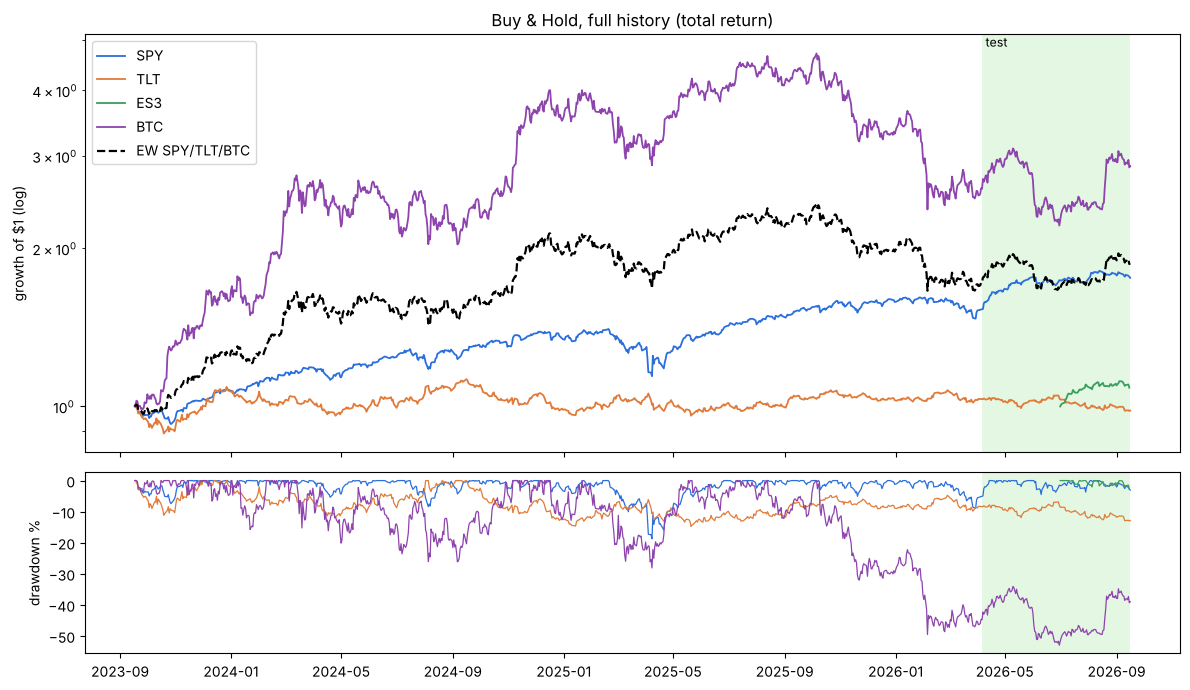

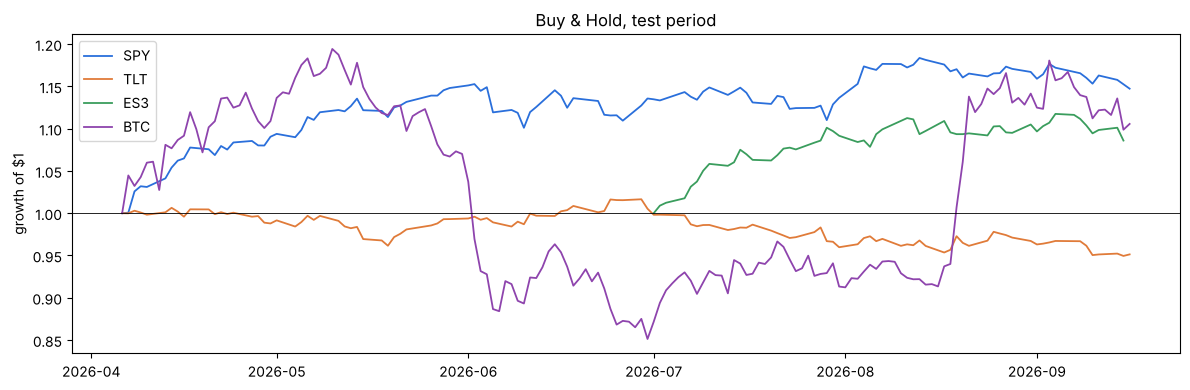

In [10]:
COLORS = {"SPY": "#2a6fdb", "TLT": "#e07b39", "ES3": "#3a9d5d", "BTC": "#8e44ad"}
test_start = pd.Timestamp(VAL_END) + pd.Timedelta(days=1)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for a, r in results["full"].items():
    eq = r.equity
    axes[0].plot(eq.index, eq / eq.iloc[0], lw=1.3, label=a, color=COLORS[a])
    axes[1].plot(eq.index, drawdown_series(eq) * 100, lw=0.9, color=COLORS[a])
eq = port["EW SPY/TLT/BTC (full)"].equity
axes[0].plot(eq.index, eq / eq.iloc[0], lw=1.6, ls="--", color="k", label="EW SPY/TLT/BTC")
axes[0].set_yscale("log")
axes[0].set_ylabel("growth of $1 (log)")
axes[0].set_title("Buy & Hold, full history (" + ("total return" if USE_ADJUSTED else "price only") + ")")
axes[1].set_ylabel("drawdown %")
for ax in axes:
    ax.axvspan(test_start, max(d.index.max() for d in daily.values()),
               color="#c8f0c8", alpha=0.5, lw=0)
axes[0].text(test_start, axes[0].get_ylim()[1], " test", va="top", fontsize=9)
axes[0].legend(loc="upper left")
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_equity_drawdown.png", dpi=130)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
for a, r in results["test"].items():
    eq = r.equity
    ax.plot(eq.index, eq / eq.iloc[0], lw=1.3, label=a, color=COLORS[a])
ax.axhline(1, color="k", lw=0.6)
ax.set_ylabel("growth of $1")
ax.set_title("Buy & Hold, test period")
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_test_period.png", dpi=130)
plt.show()

## 10. Save outputs

* `benchmark_bh_metrics_test.csv` — headline table (one column per asset, test period)
* `benchmark_bh_metrics_by_period.csv` — every asset × period
* `benchmark_bh_portfolio.csv` — equal-weight portfolio benchmarks
* `benchmark_bh_daily_closes.csv` — daily closes used (unadjusted and adjusted), handy for the
  required "daily closing prices" submission file
* two PNG charts

In [11]:
test_table.loc["window"] = windows
test_table.to_csv(RESULTS_DIR / f"{TAG}_metrics_test.csv")
by_period.to_csv(RESULTS_DIR / f"{TAG}_metrics_by_period.csv")
port_table.loc["window"] = port_windows
port_table.to_csv(RESULTS_DIR / f"{TAG}_portfolio.csv")

closes = pd.concat(sort=True, objs={**{f"{a}_close": daily_price_only[a]["close"] for a in daily},
                    **{f"{a}_adj_close": daily[a]["close"] for a in daily}}, axis=1).sort_index()
closes.to_csv(RESULTS_DIR / f"{TAG}_daily_closes.csv", float_format="%.6f")

print("ES3 source:", ES3_SOURCE)
for f in sorted(RESULTS_DIR.glob(f"{TAG}_*")):
    print("  ", f.name)

ES3 source: team 30m files only
   benchmark_bh_daily_closes.csv
   benchmark_bh_equity_drawdown.png
   benchmark_bh_metrics_by_period.csv
   benchmark_bh_metrics_test.csv
   benchmark_bh_portfolio.csv
   benchmark_bh_test_period.png
